In [1]:
!pip install -q ultralytics roboflow albumentations onnx onnxruntime scikit-learn

from roboflow import Roboflow
rf = Roboflow(api_key="YOUR_ROBOFLOW_API_KEY")

#bộ dữ liệu số 1 (5000 ảnh, 9 class)
project1 = rf.workspace("first-qkz37").project("vietnamese-currency-lgi9i")
version1 = project1.version(6)
dataset1 = version1.download("yolov8", location="raw_data_1")

#bộ dữ liệu sô 2 (2000 ảnh, 6 class polyme)
project2 = rf.workspace("tran-minh-nghia").project("vietnam-money-recognize-dy4cd-iddjh")
version2 = project2.version(1)
dataset2 = version2.download("yolov8", location="raw_data_2")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to raw_data_1 in yolov8:: 100%|██████████| 10536/10536 [00:01<00:00, 6606.51it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to raw_data_2 in yolov8:: 100%|██████████| 3848/3848 [00:00<00:00, 8157.11it/s]


In [2]:
import os
import cv2
import yaml
import numpy as np
from pathlib import Path
from tqdm import tqdm

# 10 lớp đầu ra chuẩn theo kế hoạch đồ án (9 mệnh giá + 1 lớp không phải tiền)
TARGET_CLASSES = [
    '1000', '2000', '5000', '10000', '20000',
    '50000', '100000', '200000', '500000', 'khong_phai_tien'
]

output_root = Path("data_v1")
split_map = {"train": "train", "valid": "val", "test": "test"}

# Tạo cấu trúc thư mục data_v1/train/<mệnh_giá>, data_v1/val/<mệnh_giá>, data_v1/test/<mệnh_giá>
for split in ["train", "val", "test"]:
    for cname in TARGET_CLASSES:
        (output_root / split / cname).mkdir(parents=True, exist_ok=True)

def process_yolo_dataset(raw_dir_str, prefix):
    raw_dir = Path(raw_dir_str)
    yaml_path = raw_dir / "data.yaml"
    if not yaml_path.exists():
        print(f"⚠️ Chưa tìm thấy thư mục '{raw_dir_str}'. Hãy kiểm tra lại dòng download của bộ này ở Ô 1!")
        return

    with open(yaml_path, 'r') as f:
        class_names = [str(c) for c in yaml.safe_load(f)['names']]
    print(f"\n📂 Đang xử lý '{raw_dir_str}' - Các mệnh giá có trong bộ này: {class_names}")

    count_notes = 0
    count_bg = 0

    for rf_split, our_split in split_map.items():
        img_dir = raw_dir / rf_split / "images"
        lbl_dir = raw_dir / rf_split / "labels"
        if not img_dir.exists():
            continue

        for img_path in tqdm(list(img_dir.glob("*.*")), desc=f"[{prefix} -> {our_split}]"):
            lbl_path = lbl_dir / (img_path.stem + ".txt")
            if not lbl_path.exists():
                continue

            img = cv2.imread(str(img_path))
            if img is None:
                continue
            h, w, _ = img.shape

            with open(lbl_path, "r") as f:
                lines = f.readlines()

            for idx, line in enumerate(lines):
                parts = line.strip().split()
                if len(parts) < 5:
                    continue
                cls_id = int(parts[0])
                cname = class_names[cls_id]
                if cname not in TARGET_CLASSES:
                    continue

                # Đổi tọa độ tỷ lệ (0->1) của YOLO sang tọa độ pixel thật trên ảnh
                xc, yc, bw, bh = map(float, parts[1:5])
                x1, y1 = max(0, int((xc - bw / 2) * w)), max(0, int((yc - bh / 2) * h))
                x2, y2 = min(w, int((xc + bw / 2) * w)), min(h, int((yc + bh / 2) * h))

                crop = img[y1:y2, x1:x2]
                if crop.size == 0 or (x2 - x1) < 20 or (y2 - y1) < 20:
                    continue

                # Chuẩn hóa về kích thước 224x224 theo hợp đồng module
                crop_224 = cv2.resize(crop, (224, 224))
                save_path = output_root / our_split / cname / f"{cname}_{prefix}_{img_path.stem}_{idx}.jpg"
                cv2.imwrite(str(save_path), crop_224)
                count_notes += 1

                # Cắt thêm mẫu "khong_phai_tien" từ phần nền ngoài tờ tiền (tối đa 300 ảnh)
                if count_bg < 300 and y1 > 100 and x1 > 100:
                    bg_crop = cv2.resize(img[0:y1, 0:x1], (224, 224))
                    bg_path = output_root / our_split / "khong_phai_tien" / f"bg_{prefix}_{img_path.stem}.jpg"
                    cv2.imwrite(str(bg_path), bg_crop)
                    count_bg += 1

    print(f"✅ Hoàn tất {raw_dir_str}: Đã cắt được {count_notes} ảnh tờ tiền (224x224) và {count_bg} ảnh lớp 'khong_phai_tien'!")

# Chạy cắt ảnh cho cả 2 bộ dữ liệu
process_yolo_dataset("raw_data_1", "ds1")
process_yolo_dataset("raw_data_2", "ds2")


📂 Đang xử lý 'raw_data_1' - Các mệnh giá có trong bộ này: ['1000', '10000', '100000', '2000', '20000', '200000', '5000', '50000', '500000']


[ds1 -> test]: 100%|██████████| 218/218 [00:00<00:00, 248.89it/s]


✅ Hoàn tất raw_data_1: Đã cắt được 12961 ảnh tờ tiền (224x224) và 300 ảnh lớp 'khong_phai_tien'!

📂 Đang xử lý 'raw_data_2' - Các mệnh giá có trong bộ này: ['10000', '100000', '20000', '200000', '50000', '500000']


[ds2 -> test]: 100%|██████████| 192/192 [00:00<00:00, 390.80it/s]

✅ Hoàn tất raw_data_2: Đã cắt được 1922 ảnh tờ tiền (224x224) và 300 ảnh lớp 'khong_phai_tien'!


In [3]:
import os, random, shutil

base_dir = "data_v1"
cls = "khong_phai_tien"

train_dir = os.path.join(base_dir, "train", cls)
val_dir   = os.path.join(base_dir, "val", cls)
test_dir  = os.path.join(base_dir, "test", cls)

os.makedirs(val_dir, exist_ok=True)
os.makedirs(test_dir, exist_ok=True)

# Kiểm tra trước để tránh chạy lại nhiều lần làm hao hụt tập train
if len(os.listdir(val_dir)) > 0:
    print(f"⚠️ {val_dir} đã có {len(os.listdir(val_dir))} ảnh, không chia lại.")
else:
    files = [f for f in os.listdir(train_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp'))]
    random.Random(42).shuffle(files)

    n_total = len(files)
    n_val   = int(n_total * 0.20)
    n_test  = int(n_total * 0.10)

    for f in files[:n_val]:
        shutil.move(os.path.join(train_dir, f), os.path.join(val_dir, f))
    for f in files[n_val : n_val + n_test]:
        shutil.move(os.path.join(train_dir, f), os.path.join(test_dir, f))

    print(f"✅ Đã chia xong lớp {cls} (tổng {n_total} ảnh):")
    print(f"   - train: {len(os.listdir(train_dir))}")
    print(f"   - val  : {len(os.listdir(val_dir))}")
    print(f"   - test : {len(os.listdir(test_dir))}")

✅ Đã chia xong lớp khong_phai_tien (tổng 414 ảnh):
   - train: 291
   - val  : 82
   - test : 41


In [4]:
import torch
import cv2
import numpy as np
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision.datasets import ImageFolder
import albumentations as A
from albumentations.pytorch import ToTensorV2

# 1. Pipeline Augmentation cho tập Train theo đúng Kế hoạch đồ án
train_transform = A.Compose([
    A.Rotate(limit=10, p=0.5),                        # Xoay nhỏ ±10 độ
    A.RandomRotate90(p=0.5),                          # Xoay 180 độ (kết hợp)
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.5),
    A.MotionBlur(blur_limit=3, p=0.2),
    A.GaussNoise(p=0.2),                              # Loại bỏ var_limit không tương thích phiên bản mới
    A.RandomShadow(p=0.2),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

# Tập Val và Test chỉ chuẩn hóa, không làm méo ảnh
val_test_transform = A.Compose([
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

class AlbumentationsDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        # Sử dụng allow_empty=True để tránh crash khi có thư mục rỗng không có ảnh (như khong_phai_tien ở val/test)
        self.dataset = ImageFolder(root_dir, allow_empty=True)
        self.transform = transform
        self.classes = self.dataset.classes
        self.targets = self.dataset.targets

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        img_path, label = self.dataset.samples[idx]
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        if self.transform:
            image = self.transform(image=image)['image']
        return image, label

train_dataset = AlbumentationsDataset("data_v1/train", transform=train_transform)
val_dataset   = AlbumentationsDataset("data_v1/val", transform=val_test_transform)
test_dataset  = AlbumentationsDataset("data_v1/test", transform=val_test_transform)

# 2. Tạo bộ lấy mẫu cân bằng (Balanced Sampling) cho các lớp thực tế có ảnh
class_counts = np.bincount(train_dataset.targets)
class_weights = 1.0 / np.maximum(class_counts, 1)
sample_weights = [class_weights[t] for t in train_dataset.targets]
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

# 3. Nạp vào DataLoader với Batch Size = 32
train_loader = DataLoader(train_dataset, batch_size=32, sampler=sampler, num_workers=2)
val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

print("Thứ tự 10 lớp trong mô hình:", train_dataset.classes)
print(f"Số lượng ảnh -> Train: {len(train_dataset)} | Val: {len(val_dataset)}")

Thứ tự 10 lớp trong mô hình: ['1000', '10000', '100000', '2000', '20000', '200000', '5000', '50000', '500000', 'khong_phai_tien']
Số lượng ảnh -> Train: 12991 | Val: 1523


In [5]:
import csv
import torch.nn as nn
import torch.optim as optim
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = len(train_dataset.classes)

# Khởi tạo MobileNetV3-Small (có sẵn tạ ImageNet) và chỉnh đầu ra thành 10 lớp
model = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1)
in_features = model.classifier[3].in_features
model.classifier[3] = nn.Linear(in_features, num_classes)
model = model.to(device)

# Loss function có Label Smoothing = 0.1
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

def run_epoch(model, loader, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    with torch.set_grad_enabled(is_train):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if is_train:
                optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            if is_train:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total

# ================= GIAI ĐOẠN 1: ĐÓNG BĂNG BACKBONE (5 EPOCH) =================
print("--- BẮT ĐẦU GIAI ĐOẠN 1: Đóng băng Backbone (Warm-up) ---")
for param in model.features.parameters():
    param.requires_grad = False

optimizer_stage1 = optim.AdamW(model.classifier.parameters(), lr=1e-3)

for epoch in range(1, 6):
    train_loss, train_acc = run_epoch(model, train_loader, optimizer_stage1)
    val_loss, val_acc = run_epoch(model, val_loader)
    print(f"[GĐ1 - Epoch {epoch}/5] Train Loss: {train_loss:.4f} (Acc: {train_acc*100:.2f}%) | Val Loss: {val_loss:.4f} (Acc: {val_acc*100:.2f}%)")

# ================= GIAI ĐOẠN 2: MỞ KHÓA & TINH CHỈNH (15 EPOCH) =================
print("\n--- BẮT ĐẦU GIAI ĐOẠN 2: Mở khóa Backbone (lr=1e-4, Early Stopping) ---")
for param in model.features.parameters():
    param.requires_grad = True

optimizer_stage2 = optim.AdamW(model.parameters(), lr=1e-4)
best_val_loss = float("inf")
best_val_acc = 0.0
patience, wait = 5, 0

for epoch in range(1, 16):
    train_loss, train_acc = run_epoch(model, train_loader, optimizer_stage2)
    val_loss, val_acc = run_epoch(model, val_loader)
    print(f"[GĐ2 - Epoch {epoch}/15] Train Loss: {train_loss:.4f} (Acc: {train_acc*100:.2f}%) | Val Loss: {val_loss:.4f} (Acc: {val_acc*100:.2f}%)")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_mobilenetv3.pth")
        wait = 0
        print("  -> Đã lưu mô hình tốt nhất!")
    else:
        wait += 1
        if wait >= patience:
            print("  -> Dừng sớm (Early Stopping) vì mô hình đã bão hòa!")
            break

print(f"\nHoàn tất huấn luyện! Độ chính xác Val cao nhất: {best_val_acc*100:.2f}%")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 65.2MB/s]


--- BẮT ĐẦU GIAI ĐOẠN 1: Đóng băng Backbone (Warm-up) ---
[GĐ1 - Epoch 1/5] Train Loss: 1.3626 (Acc: 63.33%) | Val Loss: 0.9040 (Acc: 85.36%)
[GĐ1 - Epoch 2/5] Train Loss: 1.1606 (Acc: 72.71%) | Val Loss: 0.8110 (Acc: 90.02%)
[GĐ1 - Epoch 3/5] Train Loss: 1.0932 (Acc: 75.71%) | Val Loss: 0.7749 (Acc: 91.53%)
[GĐ1 - Epoch 4/5] Train Loss: 1.0550 (Acc: 77.88%) | Val Loss: 0.7734 (Acc: 91.53%)
[GĐ1 - Epoch 5/5] Train Loss: 1.0451 (Acc: 77.85%) | Val Loss: 0.7414 (Acc: 92.38%)

--- BẮT ĐẦU GIAI ĐOẠN 2: Mở khóa Backbone (lr=1e-4, Early Stopping) ---
[GĐ2 - Epoch 1/15] Train Loss: 0.8701 (Acc: 86.29%) | Val Loss: 0.6537 (Acc: 96.13%)
  -> Đã lưu mô hình tốt nhất!
[GĐ2 - Epoch 2/15] Train Loss: 0.7601 (Acc: 91.29%) | Val Loss: 0.6248 (Acc: 97.05%)
  -> Đã lưu mô hình tốt nhất!
[GĐ2 - Epoch 3/15] Train Loss: 0.7160 (Acc: 93.05%) | Val Loss: 0.6140 (Acc: 97.57%)
  -> Đã lưu mô hình tốt nhất!
[GĐ2 - Epoch 4/15] Train Loss: 0.6850 (Acc: 94.35%) | Val Loss: 0.5921 (Acc: 97.90%)
  -> Đã lưu mô hình

   BÁO CÁO PHÂN LOẠI CHI TIẾT TRÊN TẬP VAL (ĐỘ CHÍNH XÁC TỪNG TỜ)
                 precision    recall  f1-score   support

           1000     0.9917    1.0000    0.9959       120
          10000     0.9622    0.9889    0.9753       180
         100000     1.0000    0.9886    0.9943       176
           2000     1.0000    1.0000    1.0000       114
          20000     0.9784    0.9731    0.9757       186
         200000     0.9888    0.9833    0.9861       180
           5000     1.0000    0.9919    0.9959       123
          50000     0.9945    0.9945    0.9945       182
         500000     0.9890    0.9944    0.9917       180
khong_phai_tien     1.0000    0.9756    0.9877        82

       accuracy                         0.9888      1523
      macro avg     0.9905    0.9890    0.9897      1523
   weighted avg     0.9890    0.9888    0.9889      1523



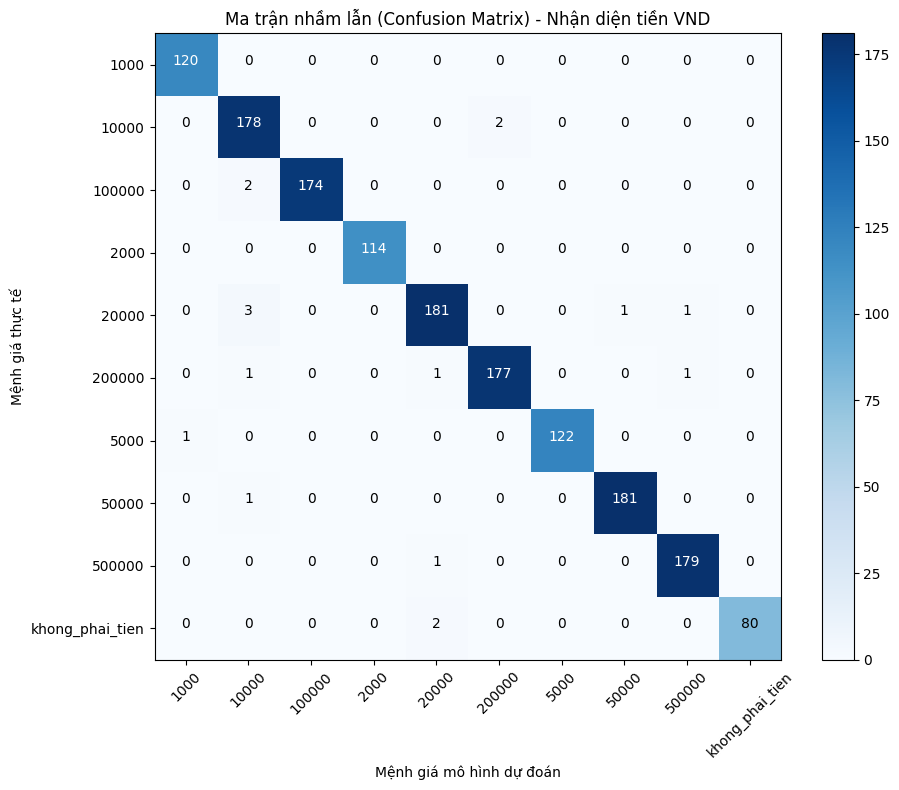

✅ Đã lưu ảnh biểu đồ vào file 'confusion_matrix.png'!


In [6]:
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

# 1. Nhận diện thiết bị (GPU hoặc CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Dựng lại khung mạng MobileNetV3-Small với 10 lớp
num_classes = len(train_dataset.classes)
model = models.mobilenet_v3_small(weights=None)
in_features = model.classifier[3].in_features
model.classifier[3] = nn.Linear(in_features, num_classes)
model = model.to(device)

# 3. Nạp lại file trọng số tốt nhất đã lưu trên đĩa
model.load_state_dict(torch.load("best_mobilenetv3.pth", map_location=device))
model.eval()

# 4. Chạy kiểm tra trên toàn bộ tập Validation
all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in val_loader:
        outputs = model(images.to(device))
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# 5. In bảng báo cáo chi tiết từng mệnh giá (Precision, Recall, F1-score)
print("=" * 65)
print("   BÁO CÁO PHÂN LOẠI CHI TIẾT TRÊN TẬP VAL (ĐỘ CHÍNH XÁC TỪNG TỜ)")
print("=" * 65)
print(classification_report(all_labels, all_preds, target_names=train_dataset.classes, digits=4))

# 6. Vẽ biểu đồ Ma trận nhầm lẫn (Confusion Matrix)
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Ma trận nhầm lẫn (Confusion Matrix) - Nhận diện tiền VND')
plt.colorbar()
tick_marks = np.arange(len(train_dataset.classes))
plt.xticks(tick_marks, train_dataset.classes, rotation=45)
plt.yticks(tick_marks, train_dataset.classes)

# Ghi số lượng lên từng ô của ma trận
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], 'd'),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

plt.ylabel('Mệnh giá thực tế')
plt.xlabel('Mệnh giá mô hình dự đoán')
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()
print("✅ Đã lưu ảnh biểu đồ vào file 'confusion_matrix.png'!")

In [ ]:
# Cài đặt bổ sung gói onnxscript cho bộ xuất ONNX mới của PyTorch
!pip install -q onnxscript

import os
import cv2
import torch
import numpy as np
import onnxruntime as ort
from google.colab import files

# 1. Xuất mô hình PyTorch ra file .onnx
os.makedirs("models", exist_ok=True)
onnx_path = "models/currency_classifier_v1.onnx"

model.cpu().eval()
dummy_input = torch.randn(1, 3, 224, 224)
torch.onnx.export(
    model, dummy_input, onnx_path,
    input_names=["input"], output_names=["output"],
    dynamic_axes={"input": {0: "batch_size"}, "output": {0: "batch_size"}},
    opset_version=13,
    dynamo=False  # Dùng trình xuất ổn định, tương thích tốt nhất với dynamic_axes
)
print(f"✅ Đã xuất thành công file mô hình: {onnx_path}")

# 2. Module chuẩn bàn giao cho Hướng 3 (Trạm quyên góp minh bạch)
class CurrencyClassifier:
    def __init__(self, model_path, class_names, conf_threshold=0.75):
        self.session = ort.InferenceSession(model_path, providers=["CPUExecutionProvider"])
        self.class_names = list(class_names)
        self.conf_threshold = float(conf_threshold)
        self.mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        self.std  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

    def _infer_probs(self, img_bgr_224):
        img_224 = cv2.resize(img_bgr_224, (224, 224))
        img_rgb = cv2.cvtColor(img_224, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        img_norm = (img_rgb - self.mean) / self.std
        tensor_in = np.transpose(img_norm, (2, 0, 1))[np.newaxis, ...]

        logits = self.session.run(["output"], {"input": tensor_in})[0][0]
        exp_logits = np.exp(logits - np.max(logits))
        return exp_logits / np.sum(exp_logits)

    def _decide(self, probs):
        best_idx = int(np.argmax(probs))
        confidence = float(probs[best_idx])
        label = self.class_names[best_idx]

        # Tách bạch 3 trạng thái:
        # - "khong_phai_tien": vật lạ / bàn tay / giấy trắng / nền trống -> từ chối ngay
        # - "khong_chac_chan": tờ tiền bị mờ / gấp / lóa dưới ngưỡng -> nhắc vuốt phẳng đặt lại
        # - Còn lại: mệnh giá hợp lệ
        if label == "khong_phai_tien":
            return "khong_phai_tien", confidence
        if confidence < self.conf_threshold:
            return "khong_chac_chan", confidence
        return label, confidence

    def predict(self, img_bgr_224):
        probs = self._infer_probs(img_bgr_224)
        return self._decide(probs)

    def predict_multi_frame(self, imgs_bgr_224):
        """Gộp xác suất trên nhiều khung hình liên tiếp (Temporal Softmax Averaging)."""
        if not imgs_bgr_224:
            raise ValueError("Danh sách ảnh đầu vào cho predict_multi_frame không được rỗng")
        avg_probs = np.mean([self._infer_probs(im) for im in imgs_bgr_224], axis=0)
        return self._decide(avg_probs)

# 3. Chạy thử nghiệm hàm phân loại trên 1 ảnh giả lập & đa khung hình
classifier = CurrencyClassifier(onnx_path, train_dataset.classes, conf_threshold=0.75)
test_dummy = np.zeros((224, 224, 3), dtype=np.uint8)
label_test, conf_test = classifier.predict(test_dummy)
label_multi, conf_multi = classifier.predict_multi_frame([test_dummy, test_dummy, test_dummy])
print(f"✅ Chạy thử nghiệm ONNX (1 khung) -> Nhãn: '{label_test}' | Độ tin cậy: {conf_test:.4f}")
print(f"✅ Chạy thử nghiệm ONNX (đa khung) -> Nhãn: '{label_multi}' | Độ tin cậy: {conf_multi:.4f}")

# 4. Tự động tải cả 3 file thành phẩm về máy tính của bạn
print("\nĐang tải các file mô hình và biểu đồ về máy tính...")
files.download(onnx_path)
files.download("best_mobilenetv3.pth")
if os.path.exists("confusion_matrix.png"):
    files.download("confusion_matrix.png")

In [8]:
# 1. Nén toàn bộ thư mục test thành 1 file zip
#!zip -r test_data.zip /content/data_v1/test
!zip -r data.zip /content/data_v1
# 2. Tự động tải file zip về máy tính của bạn
from google.colab import files
files.download('data.zip')

Kết quả truyền trực tuyến bị cắt bớt đến 5000 dòng cuối.
  adding: content/data_v1/train/500000/500000_ds1_73_jpg.rf.ec7de2df9f22290567837c2cbc55156e_2.jpg (deflated 1%)
  adding: content/data_v1/train/500000/500000_ds1_IMG_9256_jpeg.rf.c62ad39c40d93793f09c4058b1dfbb6d_0.jpg (deflated 2%)
  adding: content/data_v1/train/500000/500000_ds1_IMG_9268_jpeg.rf.dff381e397394cbff6d4b7ed2c8d4f50_0.jpg (deflated 1%)
  adding: content/data_v1/train/500000/500000_ds1_62_jpg.rf.386d918466c8e0d0b8d36db34b55f841_2.jpg (deflated 2%)
  adding: content/data_v1/train/500000/500000_ds1_1633072090718_jpg.rf.b8ac1c7d7f4ea726f0831158cc07e41f_0.jpg (deflated 1%)
  adding: content/data_v1/train/500000/500000_ds1_1175_jpg.rf.cbd86707f4a27063b3335d93c1a42549_0.jpg (deflated 1%)
  adding: content/data_v1/train/500000/500000_ds1_1287_jpg.rf.e5a2708e3366ef27f9219c9a1a346ad2_0.jpg (deflated 1%)
  adding: content/data_v1/train/500000/500000_ds1_1293_jpg.rf.fb75d7dcf41d8360975a5fc558e19892_0.jpg (deflated 1%)
  adding

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>